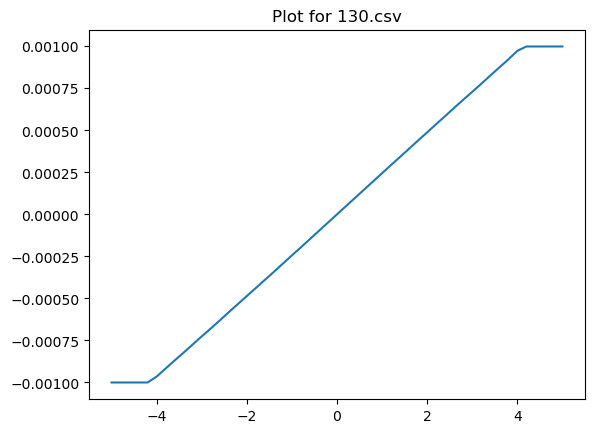

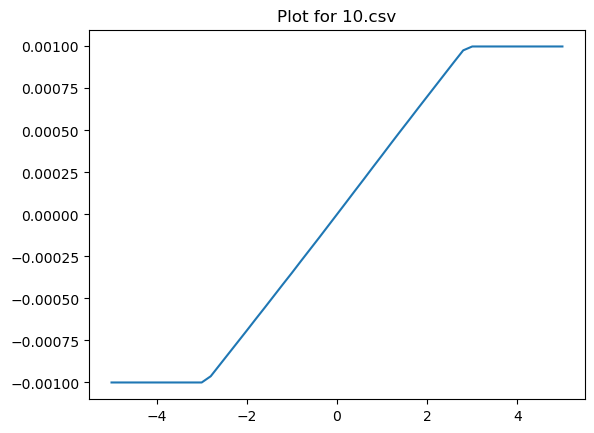

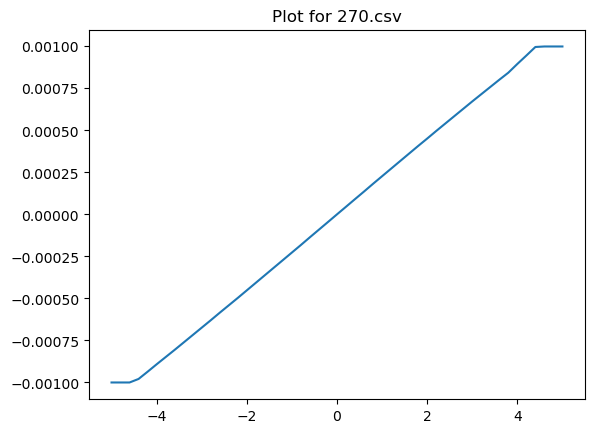

In [1]:
from IPython import display
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

folder_path = Path('TLM_IV-Sweep')
tlm_data_dict = {}
distances =[]
# Loop through all CSV files using pathlib
# Could sort it here if wanted
for file_path in folder_path.glob('*.csv'):

    # Read the current file into a Pandas DataFrame
    df = pd.read_csv(file_path)
    vi_2d_list = df[['Voltage', 'Current']].values.tolist()


    distances.append(int(file_path.stem))
    
    # 3. Add to the dictionary using the file's name (without the .csv extension) as the key
    tlm_data_dict[file_path.stem] = vi_2d_list
    # Process or plot your data here
    plt.figure()
    plt.plot(df['Voltage'], df['Current'])

    plt.title(f"Plot for {file_path.name}")
    plt.savefig(f"Graphics/{file_path.stem}_plot.png")  # Saves plot using the file's name






In [2]:
tlm_resistance = {}

for tlm, data in tlm_data_dict.items():
    # Filter the 2D list for points where Voltage (index 0) is between -1 and 1
    filtered_v = [point[0] for point in data if -1.0 <= point[0] <= 1.0]
    filtered_i = [point[1] for point in data if -1.0 <= point[0] <= 1.0]
    
    # Importing numpy here locally to respect the rule of only changing this section
    import numpy as np 
    
    # Ensure there is enough data in this range to do a regression
    if len(filtered_v) > 1:
        # np.polyfit(x, y, 1) returns [slope, intercept] for a 1st degree polynomial
        slope, intercept = np.polyfit(filtered_v, filtered_i, 1)
        
        # The slope of an I-V curve is conductance. Resistance is 1 / slope.
        tlm_resistance[tlm] = 1 / slope
    else:
        tlm_resistance[tlm] = None


print("TLM Resistances:", tlm_resistance)

TLM Resistances: {'130': np.float64(4085.6500826415577), '10': np.float64(2856.3267637817758), '270': np.float64(4403.5228182546025)}


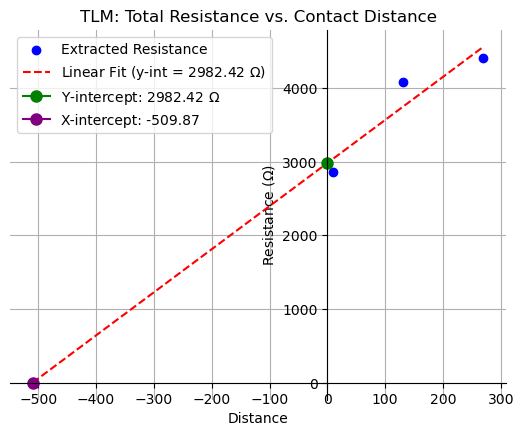

Slope: 5.849330269802511 Y intercept: 2982.424751352968 X intercept: -509.8745691878436


In [3]:
resistances = list(tlm_resistance.values())

# Create a new figure for the TLM plot
plt.figure()

# Scatter plot of the actual data points
plt.scatter(distances, resistances, color='blue', label='Extracted Resistance')

# Optional: Add a linear regression line to find Contact Resistance (y-intercept)
# np is already imported from your previous loop
slope_tlm, Yintercept_tlm = np.polyfit(distances, resistances, 1)
Xintercept_tlm = -Yintercept_tlm/slope_tlm
# Create a new list of x-values starting from the X-intercept to your max distance
x_fit = [Xintercept_tlm, max(distances)]

# Calculate the corresponding y-values (which will be 0 at the X-intercept)
y_fit = [slope_tlm * x + Yintercept_tlm for x in x_fit]

# Plot the extended line
plt.plot(x_fit, y_fit, color='red', linestyle='--', 
         label=f'Linear Fit (y-int = {Yintercept_tlm:.2f} $\Omega$)')

# Formatting the plot
plt.plot(0, Yintercept_tlm, marker='o', markersize=8, color='green', label=f'Y-intercept: {Yintercept_tlm:.2f} $\Omega$')

# Plot the X-intercept (y = 0)
plt.plot(Xintercept_tlm, 0, marker='o', markersize=8, color='purple', label=f'X-intercept: {Xintercept_tlm:.2f}')

ax = plt.gca()


# Move the bottom and left spines to x = 0 and y = 0
ax.spines['bottom'].set_position('zero')
ax.spines['left'].set_position('zero')

# Hide the top and right spines completely
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.xlabel('Distance') # Add your units here, e.g., (μm)
plt.ylabel('Resistance ($\Omega$)')
plt.title('TLM: Total Resistance vs. Contact Distance')
plt.legend()
plt.grid(True)

# Save or show the plot
plt.savefig("Graphics/TLM_Resistance_vs_Distance.png")
plt.show()

print("Slope: "+ str(slope_tlm) + " Y intercept: " + str(Yintercept_tlm)+ " X intercept: "+ str(Xintercept_tlm))



In [4]:
from IPython.display import display, Markdown

#pad width (Z) in micrometers
Z = 100.0  

# 1. Calculate the final TLM parameters based on the linear fit
R_s = slope_tlm * Z                  
R_c = Yintercept_tlm / 2             
rho_c = ((R_c * Z) ** 2) / R_s       
rho_c_cm2 = rho_c * 1e-8             
L_t = (rho_c / R_s) ** 0.5           

# 2. Assemble the complete Markdown report using
markdown_output = rf"""### Process Overview
This analysis extracts the electrical contact parameters from Transmission Line Measurement (TLM) structures evaluated during a teaching lab. 
The test structures consist of Aluminum metal contacts on a Silicon semiconductor substrate, with a silicon dioxide ($SiO_2$) dielectric layer. 
To promote the formation of an ohmic contact and reduce interfacial resistance, the wafer underwent a thermal annealing process at 400°C for 10 
minutes. The raw current-voltage (I-V) data was collected across varying contact distances using a voltage and current analyzer.

### Parameter Definitions
* **Sheet Resistance ($R_s$):** The intrinsic electrical resistance of the underlying Silicon layer.
* **Contact Resistance ($R_c$):** The resistance strictly occurring at the boundary between the Aluminum contact and the Silicon.
* **Specific Contact Resistivity ($\rho_c$):** A normalized metric of the metal-semiconductor interface quality, independent of the pad geometry.
* **Transfer Length ($L_T$):** The characteristic distance over which current transfers between the Aluminum and the Silicon.

### TLM Extraction Equations

$$R_s = \text{{slope}} \cdot Z$$

$$R_c = \frac{{\text{{Y-intercept}}}}{{2}}$$

$$\rho_c = \frac{{(R_c \cdot Z)^2}}{{R_s}}$$

$$L_T = \sqrt{{\frac{{\rho_c}}{{R_s}}}}$$

### TLM Parameter Extraction Summary

| Parameter | Value | Unit | Notes |
| :--- | :--- | :--- | :--- |
| **Pad Width (Z)** | {Z:.2f} | um | *Input parameter* |
| **Sheet Resistance (R_s)** | {R_s:.2f} | Ohms/sq | |
| **Contact Resistance (R_c)** | {R_c:.2f} | Ohms | |
| **Specific Contact Res. (rho_c)** | {rho_c_cm2:.3e} | Ohm-cm^2 | *Quality metric* |

### Conclusion and Process Evaluation
The extraction of these TLM parameters serves as a direct quantitative evaluation of the fabrication process. Specifically, the specific contact 
resistivity ($\rho_c$) provides critical feedback on the efficacy of the 400°C, 10-minute thermal anneal in establishing a high-quality ohmic 
contact at the Aluminum-Silicon interface. Validating these parameters ensures that contact resistance does not dominate the overall device 
behavior, establishing a reliable baseline for the accurate electrical characterization of accompanying structures on the wafer, such as MOSCAP 
devices.
"""

# Render the complete report
display(Markdown(markdown_output))

### Process Overview
This analysis extracts the electrical contact parameters from Transmission Line Measurement (TLM) structures evaluated during a teaching lab. 
The test structures consist of Aluminum metal contacts on a Silicon semiconductor substrate, with a silicon dioxide ($SiO_2$) dielectric layer. 
To promote the formation of an ohmic contact and reduce interfacial resistance, the wafer underwent a thermal annealing process at 400°C for 10 
minutes. The raw current-voltage (I-V) data was collected across varying contact distances using a voltage and current analyzer.

### Parameter Definitions
* **Sheet Resistance ($R_s$):** The intrinsic electrical resistance of the underlying Silicon layer.
* **Contact Resistance ($R_c$):** The resistance strictly occurring at the boundary between the Aluminum contact and the Silicon.
* **Specific Contact Resistivity ($\rho_c$):** A normalized metric of the metal-semiconductor interface quality, independent of the pad geometry.
* **Transfer Length ($L_T$):** The characteristic distance over which current transfers between the Aluminum and the Silicon.

### TLM Extraction Equations

$$R_s = \text{slope} \cdot Z$$

$$R_c = \frac{\text{Y-intercept}}{2}$$

$$\rho_c = \frac{(R_c \cdot Z)^2}{R_s}$$

$$L_T = \sqrt{\frac{\rho_c}{R_s}}$$

### TLM Parameter Extraction Summary

| Parameter | Value | Unit | Notes |
| :--- | :--- | :--- | :--- |
| **Pad Width (Z)** | 100.00 | um | *Input parameter* |
| **Sheet Resistance (R_s)** | 584.93 | Ohms/sq | |
| **Contact Resistance (R_c)** | 1491.21 | Ohms | |
| **Specific Contact Res. (rho_c)** | 3.802e-01 | Ohm-cm^2 | *Quality metric* |

### Conclusion and Process Evaluation
The extraction of these TLM parameters serves as a direct quantitative evaluation of the fabrication process. Specifically, the specific contact 
resistivity ($\rho_c$) provides critical feedback on the efficacy of the 400°C, 10-minute thermal anneal in establishing a high-quality ohmic 
contact at the Aluminum-Silicon interface. Validating these parameters ensures that contact resistance does not dominate the overall device 
behavior, establishing a reliable baseline for the accurate electrical characterization of accompanying structures on the wafer, such as MOSCAP 
devices.
